In [4]:
import pandas as pd
from scipy.io import arff

data, meta = arff.loadarff("../data/Training Dataset.arff")
df = pd.DataFrame(data)

for column in df.columns:
    if df[column].dtype == "object":
        df[column] = df[column].str.decode("utf-8").astype(int)

df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [2]:
df["Result"] = df["Result"].str.decode("utf-8").astype(int)

df["Result"].value_counts()

Result
 1    6157
-1    4898
Name: count, dtype: int64

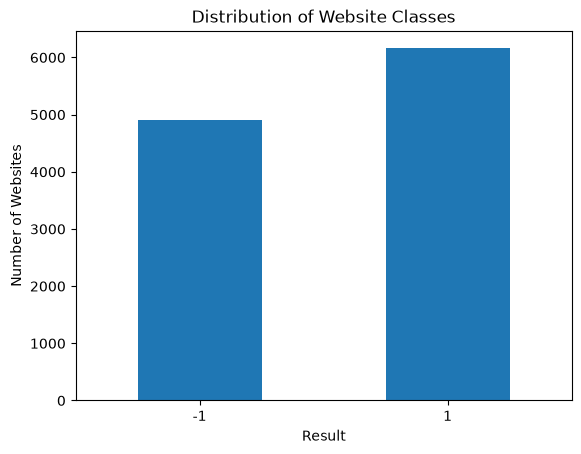

In [3]:
import matplotlib.pyplot as plt

df["Result"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Website Classes")
plt.xlabel("Result")
plt.ylabel("Number of Websites")
plt.xticks(rotation=0)
plt.show()

In [4]:
df.drop(columns="Result").nunique().value_counts()

2    22
3     8
Name: count, dtype: int64

In [5]:
for column in df.drop(columns="Result").columns:
    print(column, ":", sorted(df[column].unique()))

having_IP_Address : [b'-1', b'1']
URL_Length : [b'-1', b'0', b'1']
Shortining_Service : [b'-1', b'1']
having_At_Symbol : [b'-1', b'1']
double_slash_redirecting : [b'-1', b'1']
Prefix_Suffix : [b'-1', b'1']
having_Sub_Domain : [b'-1', b'0', b'1']
SSLfinal_State : [b'-1', b'0', b'1']
Domain_registeration_length : [b'-1', b'1']
Favicon : [b'-1', b'1']
port : [b'-1', b'1']
HTTPS_token : [b'-1', b'1']
Request_URL : [b'-1', b'1']
URL_of_Anchor : [b'-1', b'0', b'1']
Links_in_tags : [b'-1', b'0', b'1']
SFH : [b'-1', b'0', b'1']
Submitting_to_email : [b'-1', b'1']
Abnormal_URL : [b'-1', b'1']
Redirect : [b'0', b'1']
on_mouseover : [b'-1', b'1']
RightClick : [b'-1', b'1']
popUpWidnow : [b'-1', b'1']
Iframe : [b'-1', b'1']
age_of_domain : [b'-1', b'1']
DNSRecord : [b'-1', b'1']
web_traffic : [b'-1', b'0', b'1']
Page_Rank : [b'-1', b'1']
Google_Index : [b'-1', b'1']
Links_pointing_to_page : [b'-1', b'0', b'1']
Statistical_report : [b'-1', b'1']


In [6]:
feature_value_counts = {}

for column in df.drop(columns="Result").columns:
    feature_value_counts[column] = df[column].value_counts().to_dict()

feature_value_counts

{'having_IP_Address': {b'1': 7262, b'-1': 3793},
 'URL_Length': {b'-1': 8960, b'1': 1960, b'0': 135},
 'Shortining_Service': {b'1': 9611, b'-1': 1444},
 'having_At_Symbol': {b'1': 9400, b'-1': 1655},
 'double_slash_redirecting': {b'1': 9626, b'-1': 1429},
 'Prefix_Suffix': {b'-1': 9590, b'1': 1465},
 'having_Sub_Domain': {b'1': 4070, b'0': 3622, b'-1': 3363},
 'SSLfinal_State': {b'1': 6331, b'-1': 3557, b'0': 1167},
 'Domain_registeration_length': {b'-1': 7389, b'1': 3666},
 'Favicon': {b'1': 9002, b'-1': 2053},
 'port': {b'1': 9553, b'-1': 1502},
 'HTTPS_token': {b'1': 9259, b'-1': 1796},
 'Request_URL': {b'1': 6560, b'-1': 4495},
 'URL_of_Anchor': {b'0': 5337, b'-1': 3282, b'1': 2436},
 'Links_in_tags': {b'0': 4449, b'-1': 3956, b'1': 2650},
 'SFH': {b'-1': 8440, b'1': 1854, b'0': 761},
 'Submitting_to_email': {b'1': 9041, b'-1': 2014},
 'Abnormal_URL': {b'1': 9426, b'-1': 1629},
 'Redirect': {b'0': 9776, b'1': 1279},
 'on_mouseover': {b'1': 9740, b'-1': 1315},
 'RightClick': {b'1': 

### EDA Observation: Feature Value Distribution

The frequency analysis shows that the encoded values are not uniformly distributed across the features. Some features are highly concentrated around a single value, while others show a more balanced distribution across two or three possible values.

For example, `RightClick`, `Iframe`, and `Redirect` contain a large proportion of observations belonging to one encoded value, whereas features such as `having_Sub_Domain` have a more distributed representation across their possible values.

This variation in feature distributions will be investigated further to determine whether certain features provide more useful information for phishing website classification.

In [7]:
for column in df.columns:
    if df[column].dtype == "object":
        df[column] = df[column].str.decode("utf-8").astype(int)

df.dtypes.value_counts()

int64    31
Name: count, dtype: int64

In [9]:
class_means = df.groupby("Result").mean()

class_means 

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
Result,,,,,,,,,,,,,,,,,,,,,
-1,0.213557,-0.682523,0.790118,0.658228,0.770519,-1.000000,-0.209473,-0.479788,-0.098408,0.628828,...,0.908126,0.613312,0.81911,-0.074724,0.298489,-0.033891,-0.586362,0.621478,0.323193,0.657411
1,0.393536,-0.593958,0.697905,0.734286,0.718369,-0.524119,0.281468,0.832223,-0.526393,0.628390,...,0.918467,0.613448,0.81517,0.169401,0.439662,0.542797,-0.401981,0.801202,0.360565,0.769043


### EDA Observation: Feature Differences Across Classes

The class-wise mean analysis shows that the average values of several features differ between the two target classes. Some features, such as `SSLfinal_State`, `Prefix_Suffix`, and `web_traffic`, show relatively large differences between the classes, whereas other features such as `Favicon` show very similar averages.

These differences suggest that some website characteristics may have greater discriminatory information for classification. However, class-wise mean differences alone are not sufficient to determine feature importance, so feature importance and feature selection methods will be investigated in later stages.

In [10]:
mean_difference = (class_means.loc[1] - class_means.loc[-1]).abs()

mean_difference.sort_values(ascending=False)

SSLfinal_State                 1.312011
URL_of_Anchor                  0.997532
web_traffic                    0.576688
Request_URL                    0.501086
having_Sub_Domain              0.490942
Prefix_Suffix                  0.475881
Domain_registeration_length    0.427985
Links_in_tags                  0.381746
SFH                            0.338364
age_of_domain                  0.244125
Page_Rank                      0.184380
having_IP_Address              0.179979
Google_Index                   0.179724
DNSRecord                      0.141173
Statistical_report             0.111632
Shortining_Service             0.092214
URL_Length                     0.088565
Abnormal_URL                   0.086323
having_At_Symbol               0.076058
HTTPS_token                    0.059189
on_mouseover                   0.054532
double_slash_redirecting       0.052149
port                           0.050242
Links_pointing_to_page         0.037372
Submitting_to_email            0.028360


### EDA Observation: Class-wise Feature Differences

The absolute difference between the class-wise feature means was calculated to identify features exhibiting larger differences between the two target classes.

`SSLfinal_State` showed the largest difference (1.312), followed by `URL_of_Anchor` (0.998), `web_traffic` (0.577), `Request_URL` (0.501), and `having_Sub_Domain` (0.491). In contrast, features such as `Favicon`, `popUpWidnow`, and `Iframe` showed very small differences.

These results provide an initial indication of potentially discriminative features. However, mean differences alone do not represent feature importance, and formal feature selection methods will be applied later in the study.

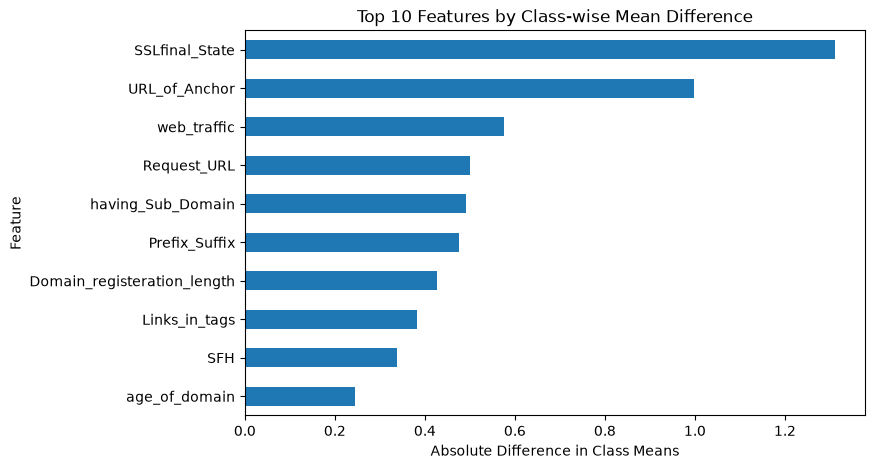

In [11]:
top_features = mean_difference.sort_values(ascending=False).head(10)

top_features.sort_values().plot(kind="barh", figsize=(8, 5))

plt.title("Top 10 Features by Class-wise Mean Difference")
plt.xlabel("Absolute Difference in Class Means")
plt.ylabel("Feature")
plt.show()

### EDA Observation: Top Features by Class-wise Mean Difference

The visualization shows the ten features with the largest absolute differences between their mean encoded values across the two target classes. `SSLfinal_State` exhibits the largest difference, followed by `URL_of_Anchor` and `web_traffic`.

The results suggest that these features may contain useful discriminatory information for distinguishing between the two website classes. However, this analysis is exploratory and does not constitute formal feature importance. Feature selection techniques will be applied in a later stage to determine which features should be retained.

In [12]:
correlation_matrix = df.corr()

correlation_matrix.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
having_IP_Address,1.000000,-0.052411,0.403461,0.158699,0.397389,-0.005257,-0.080745,0.071414,-0.022739,0.087025,...,0.096882,0.054694,-0.010446,-0.050733,0.002922,-0.091774,0.029153,-0.339065,-0.019103,0.094160
URL_Length,-0.052411,1.000000,-0.097881,-0.075108,-0.081247,0.055247,0.003997,0.048754,-0.221892,-0.042497,...,-0.049381,-0.013838,0.179426,-0.040823,0.008993,0.183518,0.002902,-0.022987,-0.067153,0.057430
Shortining_Service,0.403461,-0.097881,1.000000,0.104447,0.842796,-0.080471,-0.041916,-0.061426,0.060923,0.006101,...,0.036616,0.016581,-0.052596,0.436064,-0.047074,0.014591,0.155844,-0.198410,0.085461,-0.067966
having_At_Symbol,0.158699,-0.075108,0.104447,1.000000,0.086960,-0.011726,-0.058976,0.031220,0.015522,0.304899,...,0.290893,0.284410,-0.005499,-0.047872,0.032918,-0.064735,0.037061,-0.006080,-0.080357,0.052948
double_slash_redirecting,0.397389,-0.081247,0.842796,0.086960,1.000000,-0.085590,-0.043079,-0.036200,0.047464,0.035100,...,0.054463,0.010459,-0.050107,0.431409,-0.062369,-0.003132,0.178415,-0.194165,0.070390,-0.038608


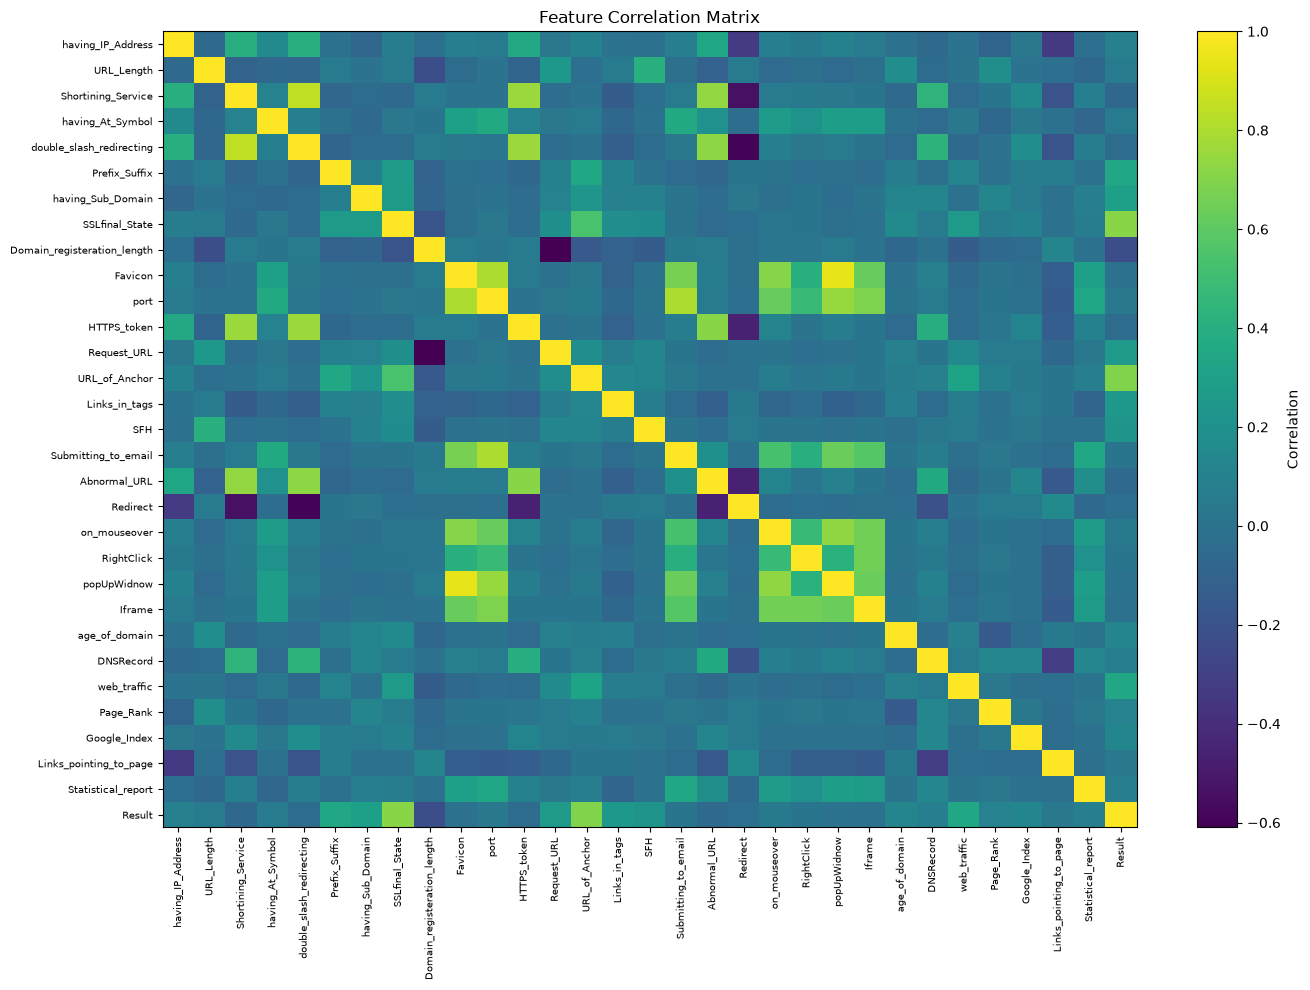

In [13]:
plt.figure(figsize=(14, 10))

plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.title("Feature Correlation Matrix")
plt.xticks(range(len(df.columns)), df.columns, rotation=90, fontsize=7)
plt.yticks(range(len(df.columns)), df.columns, fontsize=7)

plt.tight_layout()
plt.show()

### EDA Observation: Feature Correlation

The correlation matrix indicates that most feature pairs have relatively low to moderate correlations, although some stronger relationships are present. For example, `Shortining_Service` and `double_slash_redirecting` show a strong positive correlation.

The presence of correlated feature pairs suggests that some input variables may contain overlapping information. This is relevant to the feature reduction objective of the study. However, correlation alone is not sufficient to determine whether a feature should be removed, so feature selection will be evaluated using formal methods in a later stage.
### EDA Observation: Highly Correlated Feature Pairs

The analysis identified several strongly correlated feature pairs. The strongest relationship was observed between `popUpWidnow` and `Favicon` (0.940), followed by `Shortining_Service` and `double_slash_redirecting` (0.843). Other notable correlations included `port` with `Favicon` (0.804), `Submitting_to_email` with `port` (0.799), and `HTTPS_token` with `double_slash_redirecting` (0.761).

These strong relationships indicate that some features may contain overlapping information. This supports further investigation into feature selection and reduction. However, correlated features will not be removed solely on the basis of correlation; their contribution to classification performance will be evaluated in later experiments.

In [14]:
corr_pairs = correlation_matrix.drop(index="Result", columns="Result").unstack()

strong_correlations = (
    corr_pairs[corr_pairs.index.get_level_values(0) != corr_pairs.index.get_level_values(1)]
    .abs()
    .sort_values(ascending=False)
)

strong_correlations.head(10)

popUpWidnow               Favicon                     0.939633
Favicon                   popUpWidnow                 0.939633
Shortining_Service        double_slash_redirecting    0.842796
double_slash_redirecting  Shortining_Service          0.842796
port                      Favicon                     0.803834
Favicon                   port                        0.803834
Submitting_to_email       port                        0.799088
port                      Submitting_to_email         0.799088
HTTPS_token               double_slash_redirecting    0.760799
double_slash_redirecting  HTTPS_token                 0.760799
dtype: float64

In [15]:
target_correlation = df.corr()["Result"].drop("Result").abs()

target_correlation.sort_values(ascending=False)

SSLfinal_State                 0.714741
URL_of_Anchor                  0.692935
Prefix_Suffix                  0.348606
web_traffic                    0.346103
having_Sub_Domain              0.298323
Request_URL                    0.253372
Links_in_tags                  0.248229
Domain_registeration_length    0.225789
SFH                            0.221419
Google_Index                   0.128950
age_of_domain                  0.121496
Page_Rank                      0.104645
having_IP_Address              0.094160
Statistical_report             0.079857
DNSRecord                      0.075718
Shortining_Service             0.067966
Abnormal_URL                   0.060488
URL_Length                     0.057430
having_At_Symbol               0.052948
on_mouseover                   0.041838
HTTPS_token                    0.039854
double_slash_redirecting       0.038608
port                           0.036419
Links_pointing_to_page         0.032574
Redirect                       0.020113


### EDA Observation: Feature Correlation with Target

The absolute correlation between each input feature and the target variable was calculated as an initial measure of association. `SSLfinal_State` showed the strongest correlation with the target (0.715), followed by `URL_of_Anchor` (0.693), `Prefix_Suffix` (0.349), and `web_traffic` (0.346).

Several features showed very weak correlation with the target, including `Favicon`, `popUpWidnow`, and `Iframe`. These results provide an initial indication of which features may have stronger linear associations with the target.

However, correlation was used only for exploratory analysis and not as the final feature-selection criterion. Formal feature-selection techniques and model-based evaluation will be used later to determine the contribution of individual features.

In [5]:
target_correlation = df.corr()["Result"].drop("Result").abs()

target_correlation.sort_values(ascending=False).head(10)

SSLfinal_State                 0.714741
URL_of_Anchor                  0.692935
Prefix_Suffix                  0.348606
web_traffic                    0.346103
having_Sub_Domain              0.298323
Request_URL                    0.253372
Links_in_tags                  0.248229
Domain_registeration_length    0.225789
SFH                            0.221419
Google_Index                   0.128950
Name: Result, dtype: float64

In [6]:
target_corr_df = (
    target_correlation
    .sort_values(ascending=False)
    .rename("absolute_correlation")
    .reset_index()
    .rename(columns={"index": "feature"})
)

target_corr_df.to_csv(
    "../results/tables/target_feature_correlations.csv",
    index=False
)

target_corr_df.head(10)

,feature,absolute_correlation
0,SSLfinal_State,0.714741
1,URL_of_Anchor,0.692935
2,Prefix_Suffix,0.348606
3,web_traffic,0.346103
4,having_Sub_Domain,0.298323
5,Request_URL,0.253372
6,Links_in_tags,0.248229
7,Domain_registeration_length,0.225789
8,SFH,0.221419
9,Google_Index,0.128950


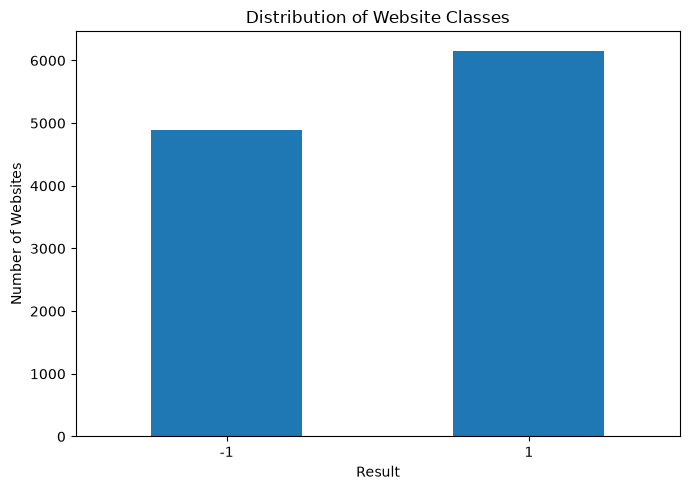

In [7]:
import matplotlib.pyplot as plt

df["Result"].value_counts().sort_index().plot(kind="bar", figsize=(7, 5))

plt.title("Distribution of Website Classes")
plt.xlabel("Result")
plt.ylabel("Number of Websites")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../results/figures/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
class_means = df.groupby("Result").mean()

mean_difference = (
    class_means.loc[1] - class_means.loc[-1]
).abs()

mean_difference.sort_values(ascending=False).head(10)

SSLfinal_State                 1.312011
URL_of_Anchor                  0.997532
web_traffic                    0.576688
Request_URL                    0.501086
having_Sub_Domain              0.490942
Prefix_Suffix                  0.475881
Domain_registeration_length    0.427985
Links_in_tags                  0.381746
SFH                            0.338364
age_of_domain                  0.244125
dtype: float64

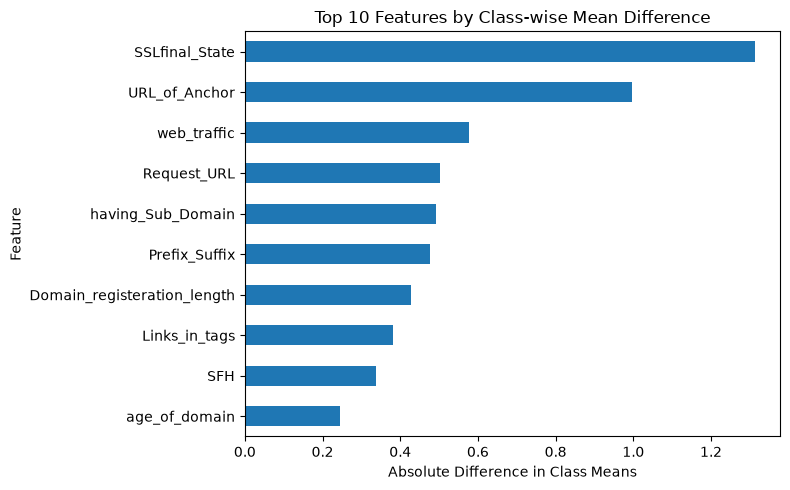

In [11]:
import matplotlib.pyplot as plt

top_features = mean_difference.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))

top_features.sort_values().plot(kind="barh")

plt.title("Top 10 Features by Class-wise Mean Difference")
plt.xlabel("Absolute Difference in Class Means")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "../results/figures/top_10_mean_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

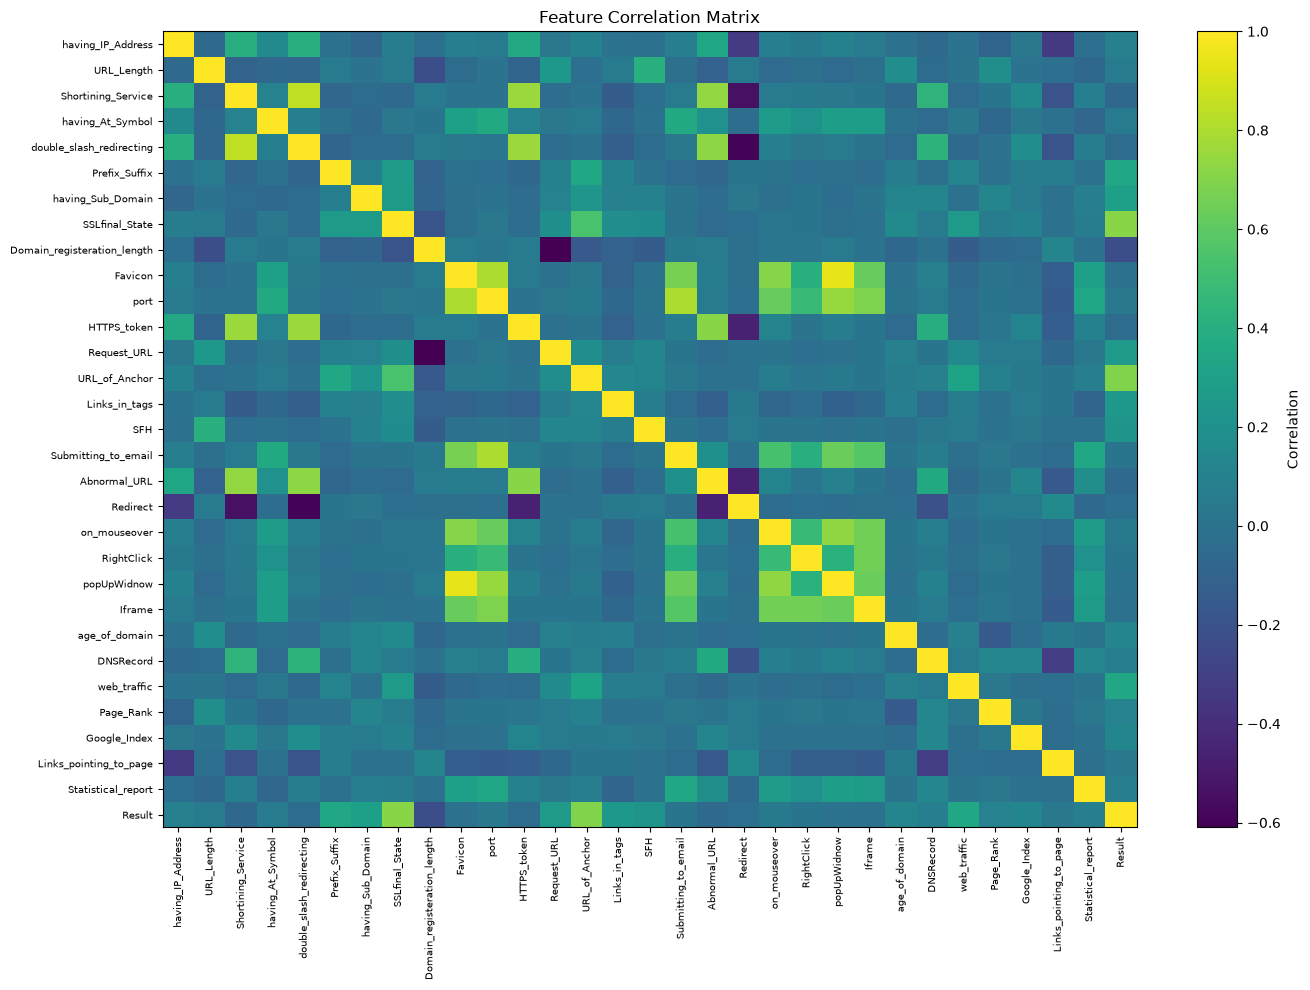

In [12]:
correlation_matrix = df.corr()

plt.figure(figsize=(14, 10))

plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.title("Feature Correlation Matrix")
plt.xticks(
    range(len(df.columns)),
    df.columns,
    rotation=90,
    fontsize=7
)
plt.yticks(
    range(len(df.columns)),
    df.columns,
    fontsize=7
)

plt.tight_layout()

plt.savefig(
    "../results/figures/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()